# Phase 3A Step 9 — Comprehensive Multivariate Analysis

## Customer Retention Intelligence System

This independent notebook explores how several variables jointly relate within the IBM
Telco development split. It uses transparent stratification and visualization—not formal
statistical adjustment, hypothesis tests, predictive models, or causal estimation.

Temporary tenure and monthly-charge groups exist only in notebook memory. They are
domain-inspired exploratory strata, not optimized or saved production features.

## 1. Independent setup and leakage-safe loading

The project root is located dynamically. Configuration is loaded with the existing
`retention.utils.config.load_config` utility, and the configured input is asserted to be
the development artifact before reading it. Previous notebooks are not imported or run.

In [1]:
# ruff: noqa: E501
import hashlib
import importlib.metadata as metadata
import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    # Find the nearest parent containing project marker files.
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (
            candidate / "params.yaml"
        ).is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from retention.utils.config import load_config  # noqa: E402

config = load_config(PROJECT_ROOT / "params.yaml")
configured_development_path = Path(config["data"]["development_path"])
assert configured_development_path == Path("data/processed/development.parquet")
development_path = (PROJECT_ROOT / configured_development_path).resolve()
assert development_path.is_file()

print(f"Project root: {PROJECT_ROOT}")
print(f"Input: {configured_development_path}")
print(f"Python: {sys.version.split()[0]} ({sys.executable})")
print(f"Configured random state preserved: {config['project']['random_state']}")
for package in ["pandas", "numpy", "matplotlib", "seaborn", "pyarrow"]:
    print(f"{package}: {metadata.version(package)}")

Project root: /Users/harshagarwal/Projects/ChurnRatePredictor
Input: data/processed/development.parquet
Python: 3.11.14 (/Users/harshagarwal/Projects/ChurnRatePredictor/.venv/bin/python)
Configured random state preserved: 42
pandas: 2.3.3
numpy: 2.4.6
matplotlib: 3.11.2
seaborn: 0.13.2
pyarrow: 26.0.1


In [2]:
# ruff: noqa: E501
import matplotlib.colors as colors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 300)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

df = pd.read_parquet(development_path)
target_column = config["data"]["target_column"]
identifier_column = config["data"]["id_column"]
numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
    "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod",
]
target_order = ["No", "Yes"]
target_colors = {"No": "#4C78A8", "Yes": "#E45756"}
overall_churn_rate = df[target_column].eq("Yes").mean()

assert df.shape == (5_634, 21)
assert set(df[target_column].unique()) == set(target_order)
print(f"Development data: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Overall churn rate: {overall_churn_rate:.2%}")
display(df.head())

Development data: 5,634 rows × 21 columns
Overall churn rate: 26.54%


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,5334-JLAXU,Female,0,Yes,No,60,Yes,Yes,Fiber optic,Yes,Yes,No,No,No,Yes,Month-to-month,Yes,Credit card (automatic),94.100,"5,475.900",No
1,4573-JKNAE,Male,0,No,Yes,12,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.350,212.300,No
2,6923-JHPMP,Female,0,No,No,2,Yes,No,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Electronic check,80.450,137.100,No
3,5524-KHNJP,Male,0,Yes,Yes,33,Yes,No,DSL,Yes,No,Yes,No,Yes,Yes,One year,No,Credit card (automatic),74.750,"2,453.300",No
4,5433-KYGHE,Female,0,No,Yes,14,Yes,Yes,Fiber optic,Yes,No,No,Yes,No,No,Month-to-month,Yes,Mailed check,86.000,"1,164.050",No


# 2. Multivariate analysis fundamentals

- **Univariate analysis** studies one variable, such as the tenure distribution.
- **Bivariate analysis** studies a pair, such as churn by contract.
- **Multivariate analysis** studies three or more variables jointly, such as churn by
  contract within tenure strata.

For outcome $Y$, exposure/category $X$, and stratifier $Z$, conditional probability is

$$P(Y=1\mid X=x,Z=z)=\frac{n(Y=1,X=x,Z=z)}{n(X=x,Z=z)}.$$

A **confounder** is associated with both an exposure and outcome and can distort their
marginal association. **Interaction** means the association between $X$ and $Y$ differs
across $Z$; **effect modification** is the substantive interpretation that the effect of
$X$ differs across levels of $Z$. Descriptive rate variation can suggest interaction but
cannot prove an effect or statistical significance.

**Simpson's paradox** is a reversal: an aggregate association points one way while the
association within relevant strata consistently points the other way. Mere attenuation or
a changing magnitude is not Simpson's paradox.

Exploratory stratification calculates separate empirical rates. Formal adjustment uses a
specified statistical/causal model, assumptions, uncertainty estimates, and diagnostics.
This notebook performs only the former. Association describes co-occurrence; causation
requires a defensible causal design and cannot be established from this observational
snapshot.

## 2.1 Temporary strata and sample-size safeguards

Tenure bands are domain-inspired lifecycle groups: 0–6, 7–12, 13–24, 25–48, and 49–72
months. Monthly-charge groups use development-data quartiles, which give approximately
equal overall counts but not equal support within every service or contract.

A cell is marked **sparse** when $0<n<30$. Missing combinations ($n=0$) remain distinct
from observed cells with zero churn ($n>0$ and churners $=0$). Sparse conditional rates
are unstable because one observation changes $\hat p=y/n$ by $1/n$; they are masked in
rate heatmaps but retained in tables and count heatmaps. The threshold is exploratory, not
an inferential guarantee. Formal confidence intervals belong to Phase 3B.

In [3]:
# ruff: noqa: E501
analysis_df = df.copy()
sparse_threshold = 30

tenure_labels = ["0–6", "7–12", "13–24", "25–48", "49–72"]
analysis_df["tenure_group"] = pd.cut(
    analysis_df["tenure"],
    bins=[-0.001, 6, 12, 24, 48, 72],
    labels=tenure_labels,
    include_lowest=True,
    ordered=True,
)

charge_quartiles = analysis_df["MonthlyCharges"].quantile([0.25, 0.50, 0.75])
charge_labels = ["Q1 low", "Q2 lower-mid", "Q3 upper-mid", "Q4 high"]
analysis_df["charge_group"] = pd.cut(
    analysis_df["MonthlyCharges"],
    bins=[-np.inf, *charge_quartiles.tolist(), np.inf],
    labels=charge_labels,
    include_lowest=True,
    ordered=True,
)

print("Temporary tenure groups:", tenure_labels)
print("Monthly-charge quartile boundaries:")
display(charge_quartiles.to_frame("boundary"))
display(analysis_df[["tenure", "tenure_group", "MonthlyCharges", "charge_group"]].head())

Temporary tenure groups: ['0–6', '7–12', '13–24', '25–48', '49–72']
Monthly-charge quartile boundaries:


,boundary
0.250,38.312
0.500,70.525
0.750,89.900


,tenure,tenure_group,MonthlyCharges,charge_group
0,60,49–72,94.100,Q4 high
1,12,7–12,19.350,Q1 low
2,2,0–6,80.450,Q3 upper-mid
3,33,25–48,74.750,Q3 upper-mid
4,14,13–24,86.000,Q3 upper-mid


In [4]:
# ruff: noqa: E501
def conditional_table(
    data: pd.DataFrame,
    row_variable: str,
    column_variable: str,
    row_order: list[str] | None = None,
    column_order: list[str] | None = None,
) -> pd.DataFrame:
    grouped = (
        data.groupby([row_variable, column_variable], observed=False)[target_column]
        .agg(
            customer_count="size",
            churned_count=lambda values: values.eq("Yes").sum(),
        )
        .reset_index()
    )
    if row_order is not None or column_order is not None:
        rows = row_order or grouped[row_variable].drop_duplicates().tolist()
        columns = column_order or grouped[column_variable].drop_duplicates().tolist()
        full_index = pd.MultiIndex.from_product(
            [rows, columns], names=[row_variable, column_variable]
        )
        grouped = (
            grouped.set_index([row_variable, column_variable])
            .reindex(full_index, fill_value=0)
            .reset_index()
        )
        grouped[row_variable] = pd.Categorical(
            grouped[row_variable], categories=rows, ordered=True
        )
        grouped[column_variable] = pd.Categorical(
            grouped[column_variable], categories=columns, ordered=True
        )
        grouped = grouped.sort_values([row_variable, column_variable]).reset_index(drop=True)
    grouped["churned_count"] = grouped["churned_count"].fillna(0).astype(int)
    grouped["customer_count"] = grouped["customer_count"].fillna(0).astype(int)
    grouped["conditional_churn_rate"] = np.where(
        grouped["customer_count"].gt(0),
        grouped["churned_count"] / grouped["customer_count"],
        np.nan,
    )
    grouped["retained_count"] = grouped["customer_count"] - grouped["churned_count"]
    grouped["retention_rate"] = 1 - grouped["conditional_churn_rate"]
    grouped["percentage_point_difference"] = (
        grouped["conditional_churn_rate"] - overall_churn_rate
    ) * 100
    grouped["missing_combination"] = grouped["customer_count"].eq(0)
    grouped["sparse_cell"] = grouped["customer_count"].between(
        1, sparse_threshold - 1
    )
    grouped["observed_zero_churn"] = (
        grouped["customer_count"].gt(0) & grouped["churned_count"].eq(0)
    )
    return grouped


def plot_heatmaps(
    table: pd.DataFrame,
    row_variable: str,
    column_variable: str,
    title: str,
) -> None:
    rate = table.pivot(
        index=row_variable,
        columns=column_variable,
        values="conditional_churn_rate",
    )
    counts = table.pivot(
        index=row_variable,
        columns=column_variable,
        values="customer_count",
    )
    churned = table.pivot(
        index=row_variable,
        columns=column_variable,
        values="churned_count",
    )
    sparse = table.pivot(
        index=row_variable,
        columns=column_variable,
        values="sparse_cell",
    )
    missing = table.pivot(
        index=row_variable,
        columns=column_variable,
        values="missing_combination",
    )

    rate_annotations = rate.copy().astype(object)
    for row in rate.index:
        for column in rate.columns:
            n = int(counts.loc[row, column])
            y = int(churned.loc[row, column])
            if bool(missing.loc[row, column]):
                label = "Missing\nn=0"
            elif bool(sparse.loc[row, column]):
                label = f"Sparse\n{y}/{n}"
            else:
                label = f"{rate.loc[row, column]:.1%}\n{y}/{n}"
            rate_annotations.loc[row, column] = label

    fig, axes = plt.subplots(1, 2, figsize=(15, max(4.5, 0.62 * len(rate.index) + 2.5)))
    sns.heatmap(
        rate,
        mask=sparse | missing,
        annot=rate_annotations,
        fmt="",
        cmap="YlOrRd",
        vmin=0,
        vmax=max(0.65, np.nanmax(rate.to_numpy())),
        cbar_kws={"label": "Conditional churn rate"},
        linewidths=0.5,
        ax=axes[0],
    )
    for row_index, row in enumerate(rate.index):
        for column_index, column in enumerate(rate.columns):
            n = int(counts.loc[row, column])
            y = int(churned.loc[row, column])
            if bool(missing.loc[row, column]):
                axes[0].text(
                    column_index + 0.5,
                    row_index + 0.5,
                    "Missing\nn=0",
                    ha="center",
                    va="center",
                    fontsize=9,
                    color="grey",
                )
            elif bool(sparse.loc[row, column]):
                axes[0].text(
                    column_index + 0.5,
                    row_index + 0.5,
                    f"Sparse\n{y}/{n}",
                    ha="center",
                    va="center",
                    fontsize=9,
                    color="darkred",
                    fontweight="bold",
                )
    axes[0].set_title("Churn rate (sparse cells masked)")
    sns.heatmap(
        counts,
        annot=True,
        fmt=".0f",
        cmap="Blues",
        cbar_kws={"label": "Customers"},
        linewidths=0.5,
        ax=axes[1],
    )
    axes[1].set_title("Customer count")
    fig.suptitle(title, fontsize=15, fontweight="bold")
    fig.tight_layout()
    plt.show()


def plot_grouped_rates(
    table: pd.DataFrame,
    x_variable: str,
    hue_variable: str,
    title: str,
) -> None:
    figure_width = max(10, 1.4 * table[x_variable].nunique() * table[hue_variable].nunique())
    fig, axis = plt.subplots(figsize=(min(18, figure_width), 5.8))
    sns.barplot(
        data=table,
        x=x_variable,
        y="conditional_churn_rate",
        hue=hue_variable,
        edgecolor="white",
        ax=axis,
    )
    axis.axhline(
        overall_churn_rate,
        color="black",
        linestyle="--",
        linewidth=1.4,
        label=f"Overall: {overall_churn_rate:.1%}",
    )
    axis.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    axis.set(title=title, xlabel=x_variable, ylabel="Conditional churn rate")
    axis.tick_params(axis="x", rotation=25)
    axis.legend(title=hue_variable, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

# 3. Contract, tenure, and churn

This analysis estimates $P(Churn=Yes\mid Contract,TenureGroup)$. Comparing contract types
within the same broad tenure band reduces—but does not eliminate—lifecycle confounding.
Bands remain heterogeneous, contract selection is non-random, and other variables are not
controlled. Therefore this is exploratory stratification, not causal adjustment.

,Contract,tenure_group,customer_count,churned_count,conditional_churn_rate,retained_count,retention_rate,percentage_point_difference,missing_combination,sparse_cell,observed_zero_churn
0,Month-to-month,0–6,1130,625,0.553,505,0.447,28.774,False,False,False
1,Month-to-month,7–12,456,195,0.428,261,0.572,16.228,False,False,False
2,Month-to-month,13–24,584,219,0.375,365,0.625,10.965,False,False,False
3,Month-to-month,25–48,653,217,0.332,436,0.668,6.696,False,False,False
4,Month-to-month,49–72,272,70,0.257,202,0.743,-0.800,False,False,False
5,One year,0–6,36,3,0.083,33,0.917,-18.202,False,False,False
6,One year,7–12,78,9,0.115,69,0.885,-14.997,False,False,False
7,One year,13–24,159,15,0.094,144,0.906,-17.101,False,False,False
8,One year,25–48,401,39,0.097,362,0.903,-16.810,False,False,False
9,One year,49–72,504,64,0.127,440,0.873,-13.837,False,False,False


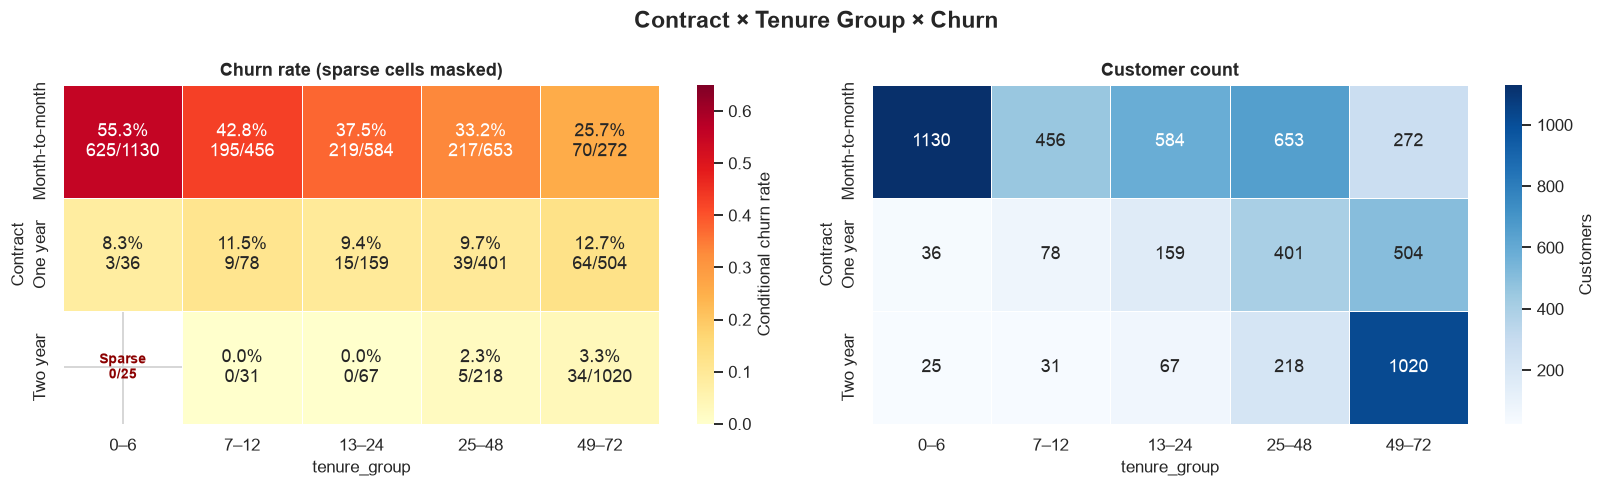

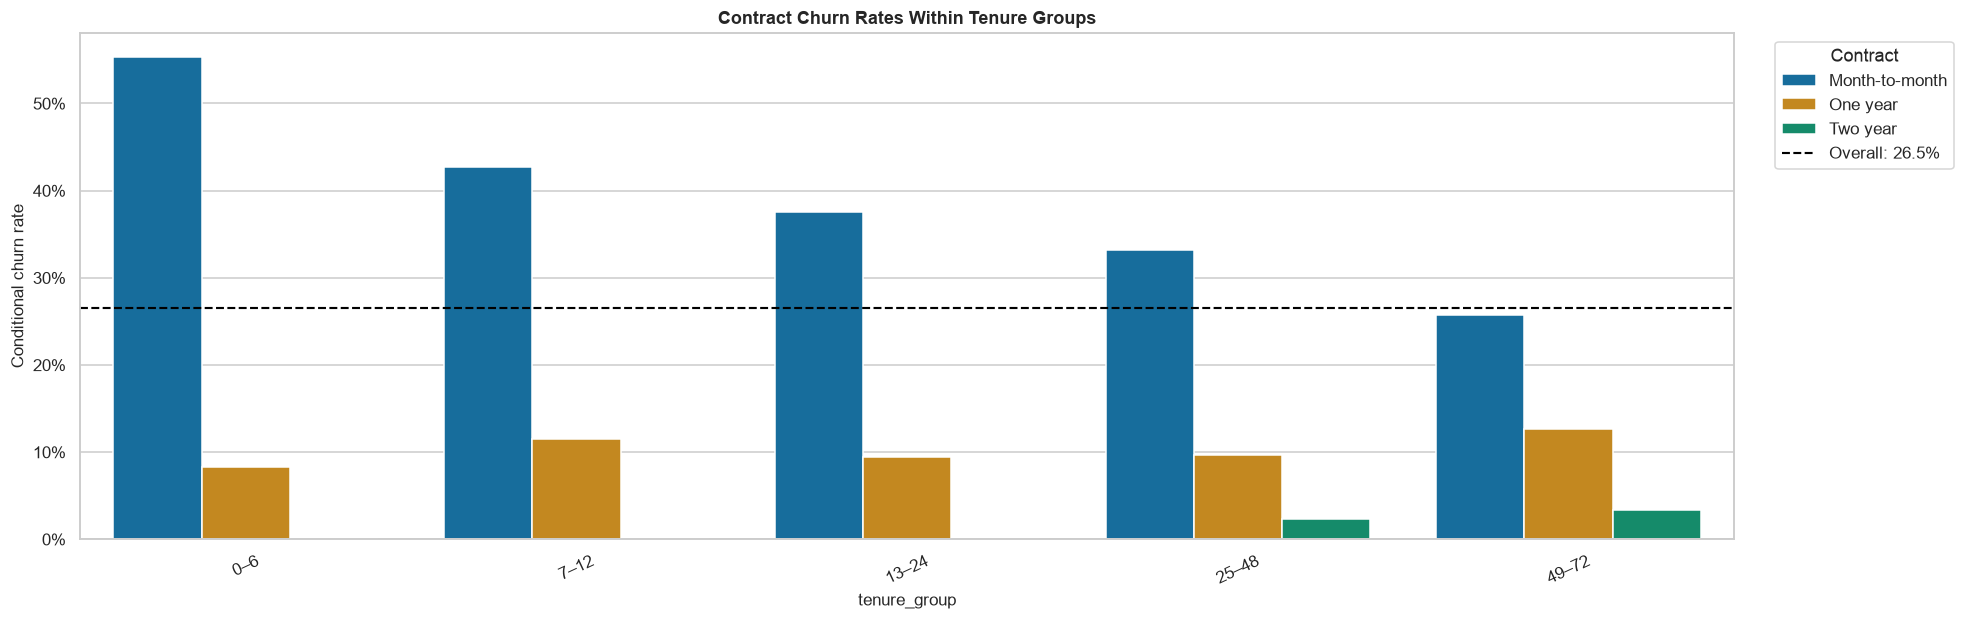

In [5]:
# ruff: noqa: E501
contract_order = ["Month-to-month", "One year", "Two year"]
contract_tenure = conditional_table(
    analysis_df,
    "Contract",
    "tenure_group",
    contract_order,
    tenure_labels,
)
display(contract_tenure)
plot_heatmaps(
    contract_tenure,
    "Contract",
    "tenure_group",
    "Contract × Tenure Group × Churn",
)
plot_grouped_rates(
    contract_tenure,
    "tenure_group",
    "Contract",
    "Contract Churn Rates Within Tenure Groups",
)

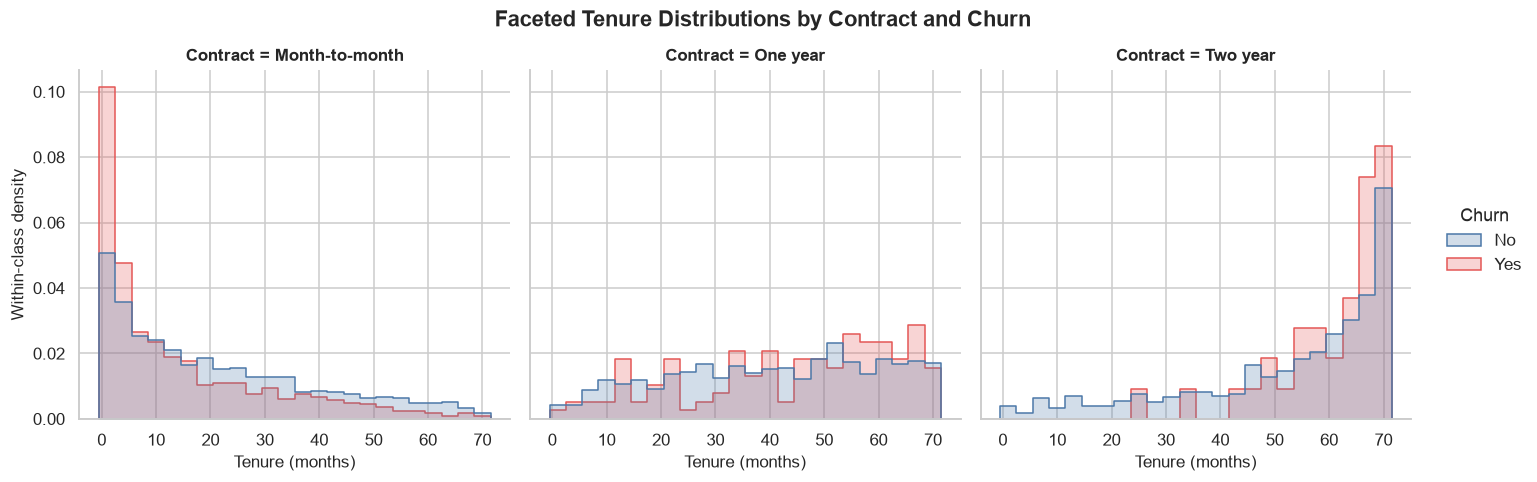

In [6]:
# ruff: noqa: E501
contract_tenure_grid = sns.displot(
    data=analysis_df,
    x="tenure",
    hue=target_column,
    hue_order=target_order,
    palette=target_colors,
    col="Contract",
    col_order=contract_order,
    kind="hist",
    stat="density",
    common_norm=False,
    element="step",
    bins=np.arange(-0.5, 73.5, 3),
    height=4.2,
    aspect=1.05,
)
contract_tenure_grid.set_axis_labels("Tenure (months)", "Within-class density")
contract_tenure_grid.fig.suptitle(
    "Faceted Tenure Distributions by Contract and Churn",
    y=1.04,
    fontweight="bold",
)
plt.show()

**Observed finding.** Month-to-month remains the highest-rate contract within every tenure
band: 55.31% at 0–6 months, declining to 25.74% at 49–72 months. One-year rates range from
8.33% to 12.70%, and two-year rates from 0% to 3.33%. Thus the marginal contract pattern
persists after coarse tenure stratification, although its magnitude varies. The two-year,
0–6-month cell contains only 25 customers and zero churners; it is sparse and masked, so
its 0% must not be presented as a reliable segment estimate.

# 4. Payment method, tenure, and churn

The bivariate electronic-check rate may be confounded by shorter tenure. We compare
$P(Churn\mid PaymentMethod,TenureGroup)$ and display both counts and rates. Persisting
differences within bands support an association that is not explained solely by these
coarse tenure groups; they do not show that changing payment method would change churn.

,PaymentMethod,tenure_group,customer_count,churned_count,conditional_churn_rate,retained_count,retention_rate,percentage_point_difference,missing_combination,sparse_cell,observed_zero_churn
0,Electronic check,0–6,540,364,0.674,176,0.326,40.872,False,False,False
1,Electronic check,7–12,228,115,0.504,113,0.496,23.903,False,False,False
2,Electronic check,13–24,298,149,0.500,149,0.500,23.465,False,False,False
3,Electronic check,25–48,416,140,0.337,276,0.663,7.119,False,False,False
4,Electronic check,49–72,395,87,0.220,308,0.780,-4.510,False,False,False
5,Mailed check,0–6,453,172,0.380,281,0.620,11.434,False,False,False
6,Mailed check,7–12,170,34,0.200,136,0.800,-6.535,False,False,False
7,Mailed check,13–24,220,21,0.095,199,0.905,-16.990,False,False,False
8,Mailed check,25–48,246,20,0.081,226,0.919,-18.405,False,False,False
9,Mailed check,49–72,207,3,0.014,204,0.986,-25.086,False,False,False


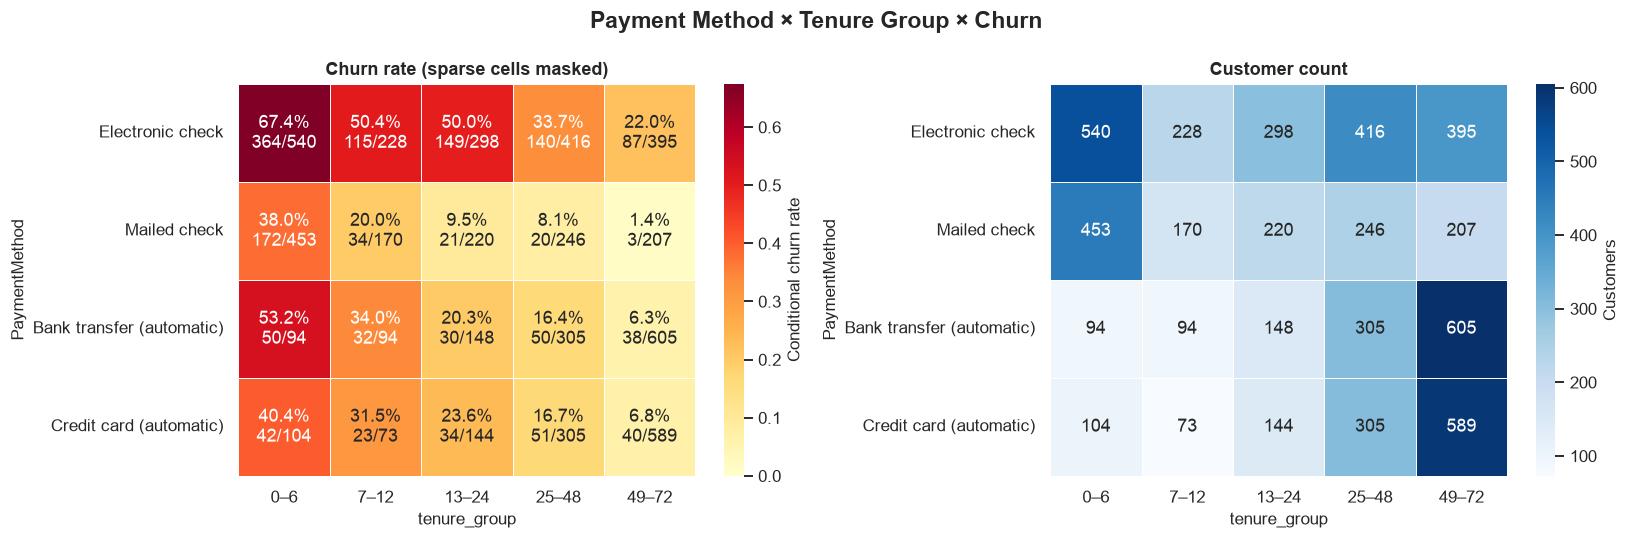

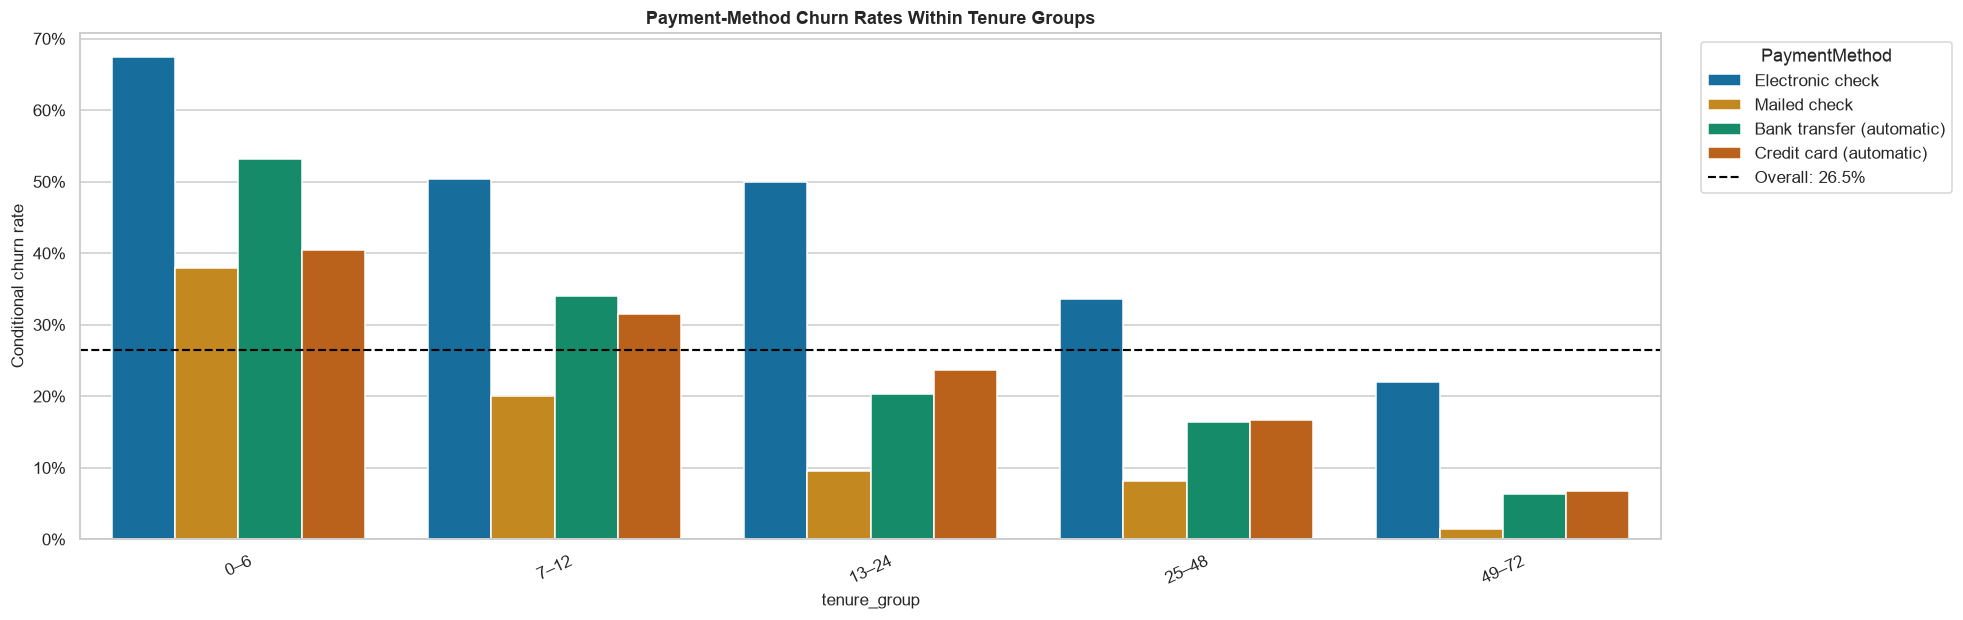

In [7]:
# ruff: noqa: E501
payment_order = [
    "Electronic check",
    "Mailed check",
    "Bank transfer (automatic)",
    "Credit card (automatic)",
]
payment_tenure = conditional_table(
    analysis_df,
    "PaymentMethod",
    "tenure_group",
    payment_order,
    tenure_labels,
)
display(payment_tenure)
plot_heatmaps(
    payment_tenure,
    "PaymentMethod",
    "tenure_group",
    "Payment Method × Tenure Group × Churn",
)
plot_grouped_rates(
    payment_tenure,
    "tenure_group",
    "PaymentMethod",
    "Payment-Method Churn Rates Within Tenure Groups",
)

**Observed finding.** Electronic check remains highest in every tenure band: 67.41%,
50.44%, 50.00%, 33.65%, and 22.03% from the newest to longest-tenured group. All payment
cells have at least 73 customers. The rate declines with tenure for every method, showing
strong lifecycle composition, but the electronic-check excess persists within the chosen
bands. This is compatible with both confounding and a remaining conditional association;
it is not evidence that payment-method conversion is an effective intervention.

# 5. Internet service, monthly charges, and churn

Charge bands use development quartiles: Q1 ≤ 38.31, Q2 ≤ 70.53, Q3 ≤ 89.90, and Q4 above
89.90. We compare service types only where their price distributions overlap. Empty cells
are substantively important: no-internet customers occur only in Q1, while fibre has no Q1
observations. Lack of common support prevents like-for-like comparisons across all strata.

,InternetService,charge_group,customer_count,churned_count,conditional_churn_rate,retained_count,retention_rate,percentage_point_difference,missing_combination,sparse_cell,observed_zero_churn
0,DSL,Q1 low,202,69,0.342,133,0.658,7.623,False,False,False
1,DSL,Q2 lower-mid,1268,272,0.215,996,0.785,-5.084,False,False,False
2,DSL,Q3 upper-mid,429,27,0.063,402,0.937,-20.242,False,False,False
3,DSL,Q4 high,35,0,0.000,35,1.000,-26.535,False,False,True
4,Fiber optic,Q1 low,0,0,NaN,0,NaN,NaN,True,False,False
5,Fiber optic,Q2 lower-mid,140,85,0.607,55,0.393,34.179,False,False,False
6,Fiber optic,Q3 upper-mid,981,494,0.504,487,0.496,23.821,False,False,False
7,Fiber optic,Q4 high,1372,458,0.334,914,0.666,6.847,False,False,False
8,No,Q1 low,1207,90,0.075,1117,0.925,-19.079,False,False,False
9,No,Q2 lower-mid,0,0,NaN,0,NaN,NaN,True,False,False


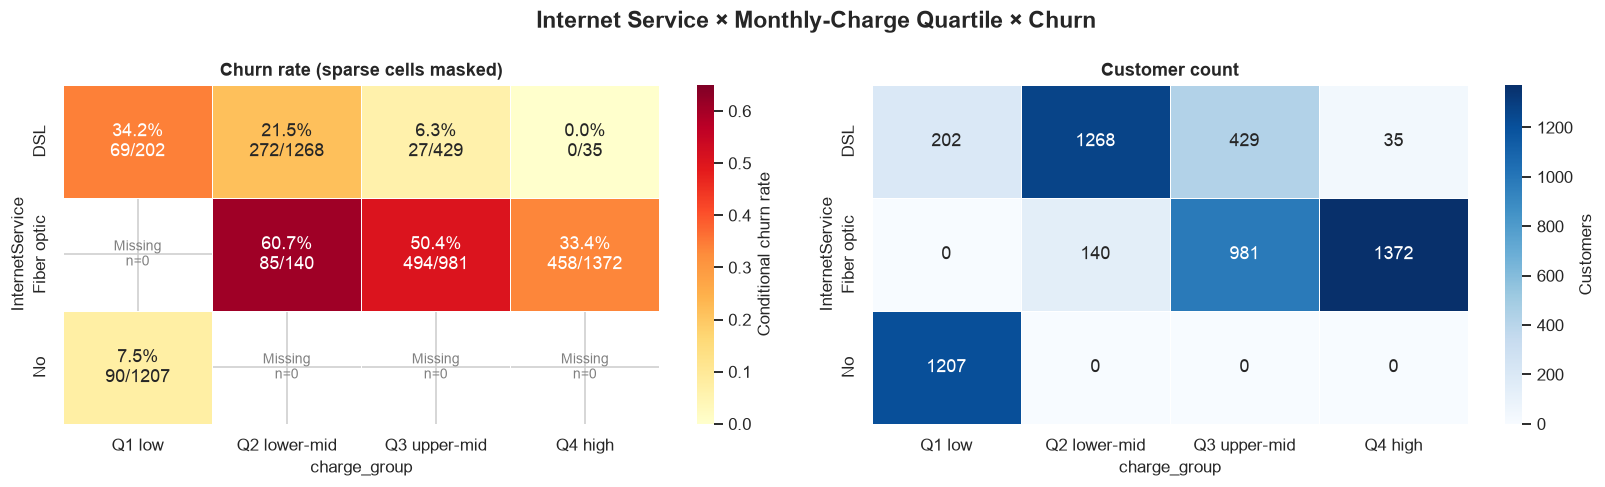

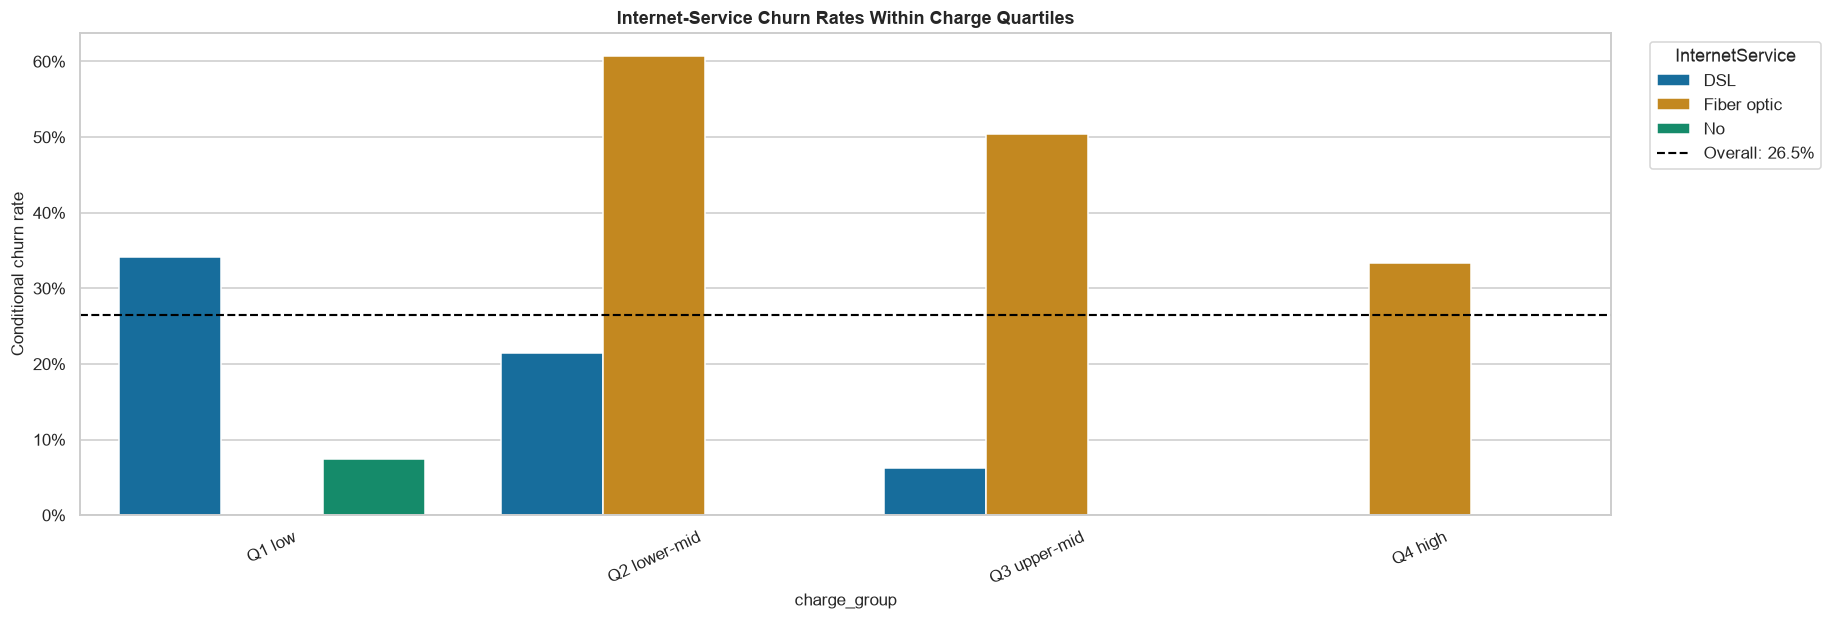

In [8]:
# ruff: noqa: E501
internet_order = ["DSL", "Fiber optic", "No"]
internet_charge = conditional_table(
    analysis_df,
    "InternetService",
    "charge_group",
    internet_order,
    charge_labels,
)
display(internet_charge)
plot_heatmaps(
    internet_charge,
    "InternetService",
    "charge_group",
    "Internet Service × Monthly-Charge Quartile × Churn",
)
plot_grouped_rates(
    internet_charge,
    "charge_group",
    "InternetService",
    "Internet-Service Churn Rates Within Charge Quartiles",
)

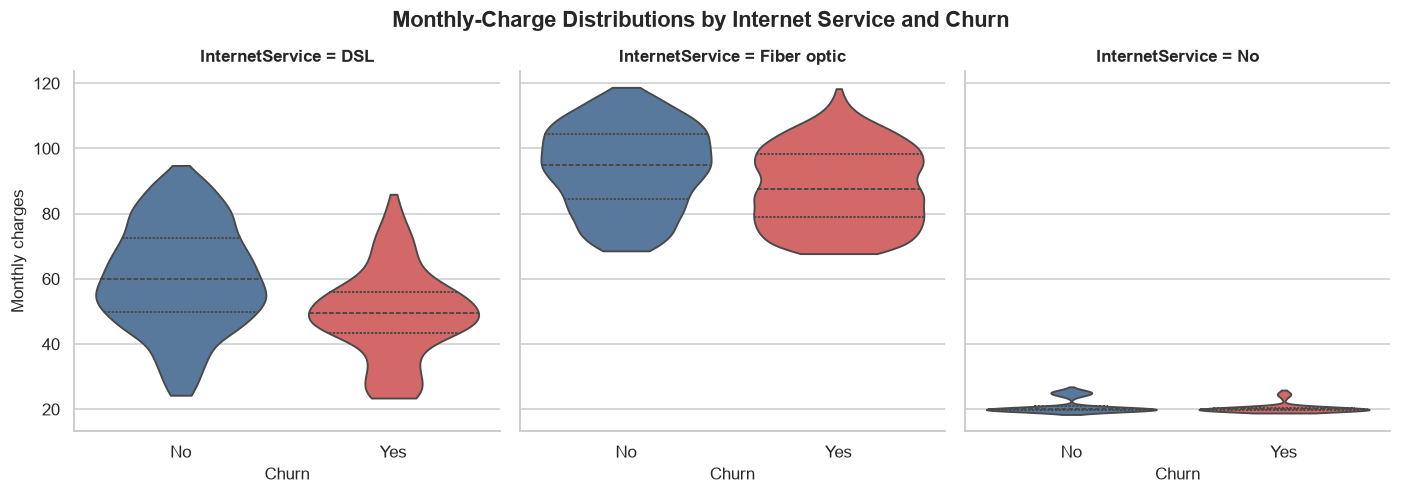

In [9]:
# ruff: noqa: E501
internet_charge_grid = sns.catplot(
    data=analysis_df,
    x=target_column,
    y="MonthlyCharges",
    order=target_order,
    hue=target_column,
    palette=target_colors,
    legend=False,
    col="InternetService",
    col_order=internet_order,
    kind="violin",
    inner="quartile",
    cut=0,
    height=4.3,
    aspect=1.0,
)
internet_charge_grid.set_axis_labels("Churn", "Monthly charges")
internet_charge_grid.fig.suptitle(
    "Monthly-Charge Distributions by Internet Service and Churn",
    y=1.04,
    fontweight="bold",
)
plt.show()

**Observed finding.** Fibre remains above DSL wherever both are observed: 60.71% versus
21.45% in Q2, 50.36% versus 6.29% in Q3, and 33.38% versus 0% in Q4. The Q4 DSL cell has 35
customers and zero churners—observed, not missing, but still near the sparsity threshold.
No-internet customers cannot be compared outside Q1, and fibre cannot be compared in Q1.
Limited overlap means price stratification does not fully isolate a service-type
association.

# 6. Customer support, security, and internet service

Structural `No internet service` is not ordinary non-adoption. Full-population tables
preserve that state. A separate subscriber subgroup is explicitly defined as
`InternetService != 'No'`; within it, support and security contain only `Yes`/`No`.

The subgroup rates estimate association among internet subscribers, not the causal effect
of purchasing support or security. Customers self-select services, and plan, tenure,
charges, need, and experience may confound adoption.

**Internet service × technical support**

,InternetService,TechSupport,customer_count,churned_count,conditional_churn_rate,retained_count,retention_rate,percentage_point_difference,missing_combination,sparse_cell,observed_zero_churn
0,DSL,No,999,276,0.276,723,0.724,1.092,False,False,False
1,DSL,Yes,935,92,0.098,843,0.902,-16.696,False,False,False
2,DSL,No internet service,0,0,NaN,0,NaN,NaN,True,False,False
3,Fiber optic,No,1787,887,0.496,900,0.504,23.101,False,False,False
4,Fiber optic,Yes,706,150,0.212,556,0.788,-5.289,False,False,False
5,Fiber optic,No internet service,0,0,NaN,0,NaN,NaN,True,False,False
6,No,No,0,0,NaN,0,NaN,NaN,True,False,False
7,No,Yes,0,0,NaN,0,NaN,NaN,True,False,False
8,No,No internet service,1207,90,0.075,1117,0.925,-19.079,False,False,False


**Internet service × online security**

,InternetService,OnlineSecurity,customer_count,churned_count,conditional_churn_rate,retained_count,retention_rate,percentage_point_difference,missing_combination,sparse_cell,observed_zero_churn
0,DSL,No,989,275,0.278,714,0.722,1.271,False,False,False
1,DSL,Yes,945,93,0.098,852,0.902,-16.694,False,False,False
2,DSL,No internet service,0,0,NaN,0,NaN,NaN,True,False,False
3,Fiber optic,No,1827,892,0.488,935,0.512,22.288,False,False,False
4,Fiber optic,Yes,666,145,0.218,521,0.782,-4.764,False,False,False
5,Fiber optic,No internet service,0,0,NaN,0,NaN,NaN,True,False,False
6,No,No,0,0,NaN,0,NaN,NaN,True,False,False
7,No,Yes,0,0,NaN,0,NaN,NaN,True,False,False
8,No,No internet service,1207,90,0.075,1117,0.925,-19.079,False,False,False


**Subscriber subgroup only: 4,427 customers**

,TechSupport,OnlineSecurity,customer_count,churned_count,conditional_churn_rate,retained_count,retention_rate,percentage_point_difference,missing_combination,sparse_cell,observed_zero_churn
0,No,No,2050,1003,0.489,1047,0.511,22.392,False,False,False
1,No,Yes,736,160,0.217,576,0.783,-4.796,False,False,False
2,Yes,No,766,164,0.214,602,0.786,-5.125,False,False,False
3,Yes,Yes,875,78,0.089,797,0.911,-17.621,False,False,False


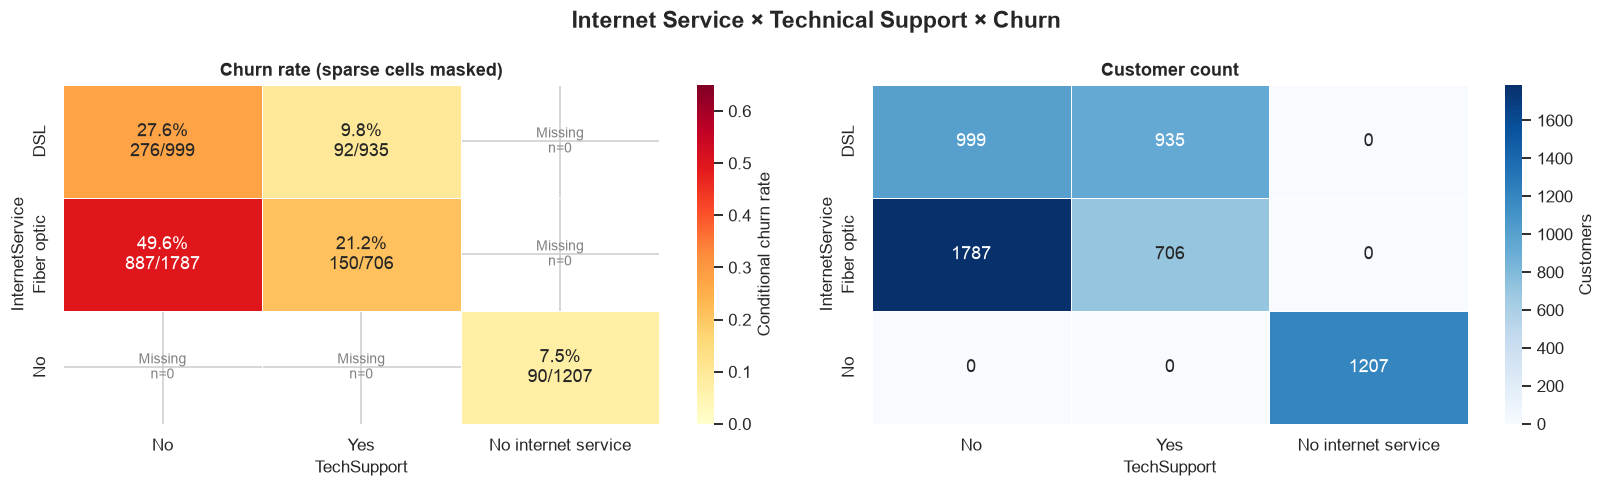

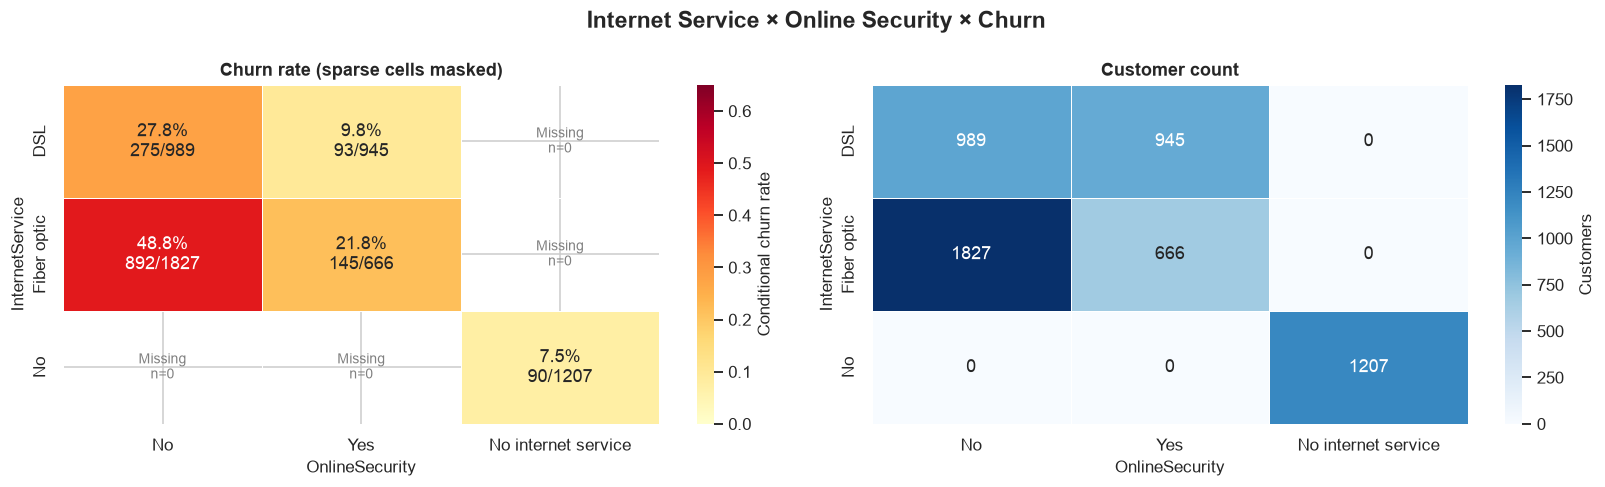

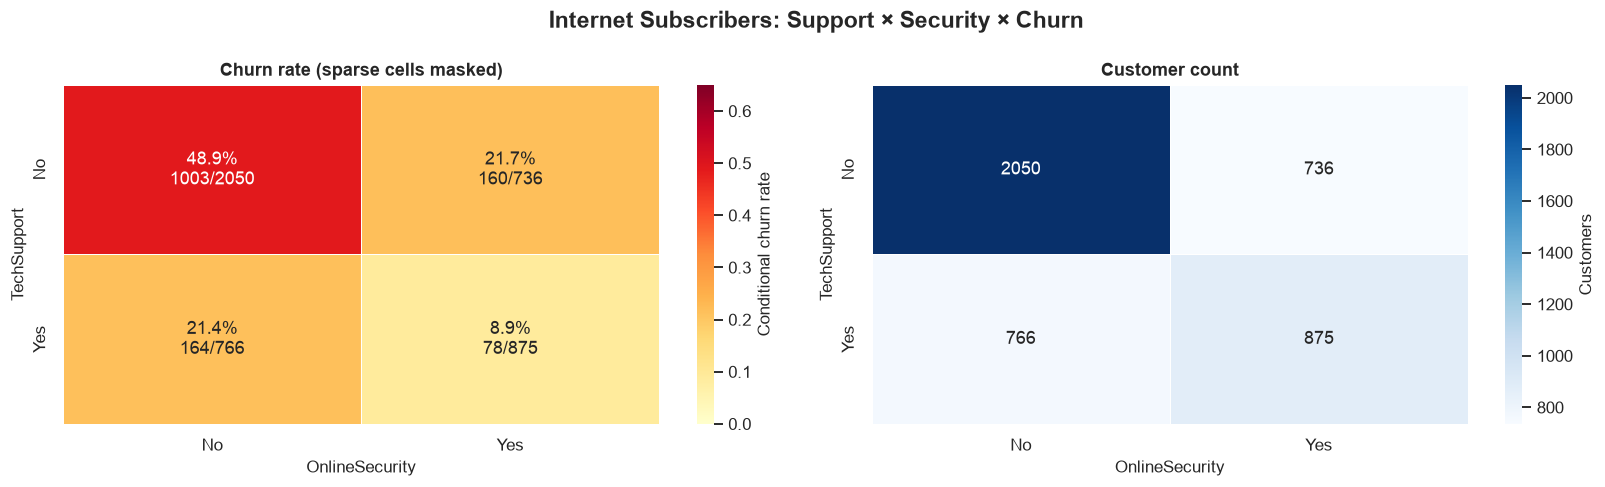

In [10]:
# ruff: noqa: E501
internet_tech = conditional_table(
    analysis_df,
    "InternetService",
    "TechSupport",
    internet_order,
    ["No", "Yes", "No internet service"],
)
internet_security = conditional_table(
    analysis_df,
    "InternetService",
    "OnlineSecurity",
    internet_order,
    ["No", "Yes", "No internet service"],
)

internet_subscribers = analysis_df.loc[analysis_df["InternetService"].ne("No")].copy()
tech_security_subscribers = conditional_table(
    internet_subscribers,
    "TechSupport",
    "OnlineSecurity",
    ["No", "Yes"],
    ["No", "Yes"],
)

display(Markdown("**Internet service × technical support**"))
display(internet_tech)
display(Markdown("**Internet service × online security**"))
display(internet_security)
display(Markdown(f"**Subscriber subgroup only: {len(internet_subscribers):,} customers**"))
display(tech_security_subscribers)

plot_heatmaps(
    internet_tech,
    "InternetService",
    "TechSupport",
    "Internet Service × Technical Support × Churn",
)
plot_heatmaps(
    internet_security,
    "InternetService",
    "OnlineSecurity",
    "Internet Service × Online Security × Churn",
)
plot_heatmaps(
    tech_security_subscribers,
    "TechSupport",
    "OnlineSecurity",
    "Internet Subscribers: Support × Security × Churn",
)

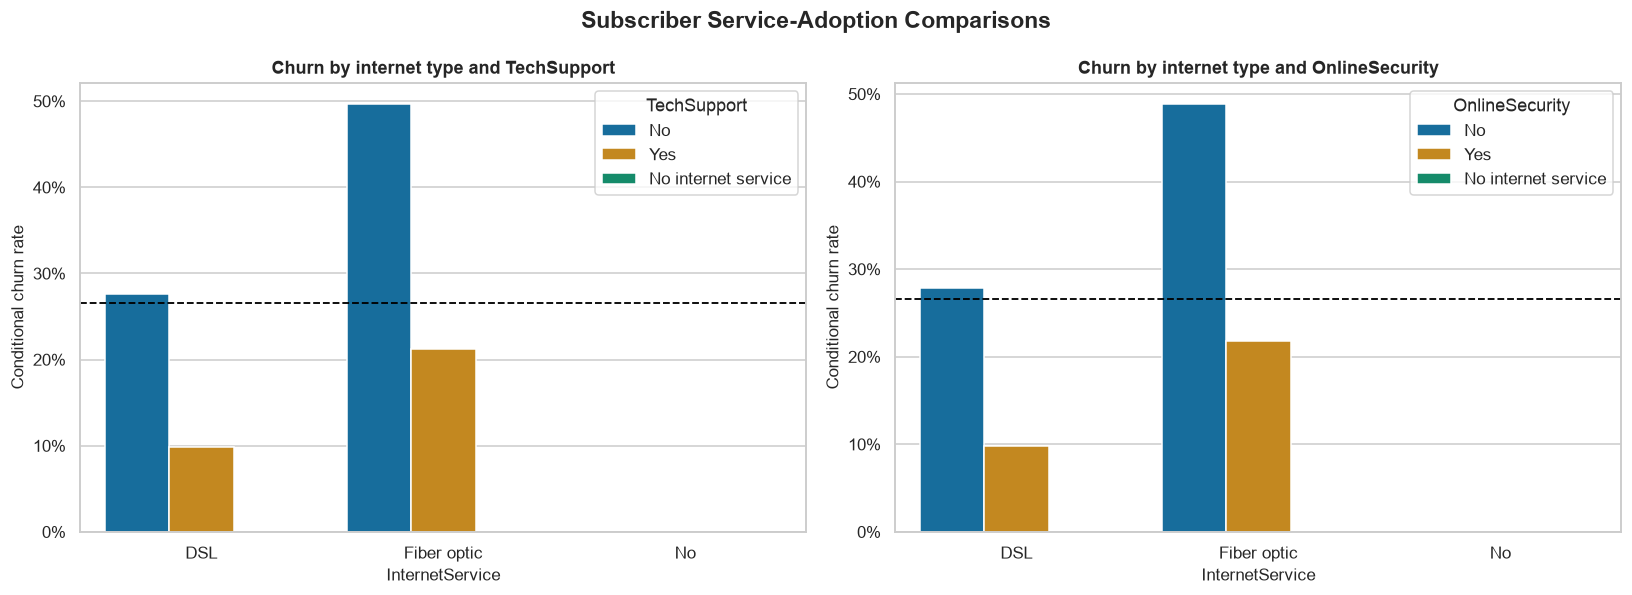

In [11]:
# ruff: noqa: E501
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
subscriber_service_tables = [
    (internet_tech.loc[internet_tech["InternetService"].ne("No") & internet_tech["TechSupport"].isin(["No", "Yes"])], "TechSupport"),
    (internet_security.loc[internet_security["InternetService"].ne("No") & internet_security["OnlineSecurity"].isin(["No", "Yes"])], "OnlineSecurity"),
]
for axis, (table, service_feature) in zip(axes, subscriber_service_tables, strict=True):
    sns.barplot(
        data=table,
        x="InternetService",
        y="conditional_churn_rate",
        hue=service_feature,
        ax=axis,
    )
    axis.axhline(overall_churn_rate, color="black", linestyle="--", linewidth=1.2)
    axis.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    axis.set(title=f"Churn by internet type and {service_feature}", ylabel="Conditional churn rate")
fig.suptitle("Subscriber Service-Adoption Comparisons", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

**Observed finding.** Within DSL, no technical support shows 27.63% churn versus 9.84%
with support; within fibre, rates are 49.64% versus 21.25%. Online-security contrasts are
similar: 27.81% versus 9.84% for DSL and 48.82% versus 21.77% for fibre. Among 4,427
internet subscribers, churn is 48.93% when both support and security are absent, 21–22%
when exactly one is present, and 8.91% when both are present. All cells are well-supported,
but selection and service context prevent causal interpretation.

# 7. Contract, monthly charges, and churn

This table estimates $P(Churn\mid Contract,ChargeGroup)$. It asks whether price-related
patterns look similar across commitment levels. The resulting combinations are exploratory
segments, not validated prediction rules or intervention targets.

,Contract,charge_group,customer_count,churned_count,conditional_churn_rate,retained_count,retention_rate,percentage_point_difference,missing_combination,sparse_cell,observed_zero_churn
0,Month-to-month,Q1 low,575,146,0.254,429,0.746,-1.144,False,False,False
1,Month-to-month,Q2 lower-mid,880,320,0.364,560,0.636,9.828,False,False,False
2,Month-to-month,Q3 upper-mid,945,496,0.525,449,0.475,25.951,False,False,False
3,Month-to-month,Q4 high,695,364,0.524,331,0.476,25.839,False,False,False
4,One year,Q1 low,323,8,0.025,315,0.975,-24.059,False,False,False
5,One year,Q2 lower-mid,301,31,0.103,270,0.897,-16.236,False,False,False
6,One year,Q3 upper-mid,201,21,0.104,180,0.896,-16.088,False,False,False
7,One year,Q4 high,353,70,0.198,283,0.802,-6.705,False,False,False
8,Two year,Q1 low,511,5,0.010,506,0.990,-25.557,False,False,False
9,Two year,Q2 lower-mid,227,6,0.026,221,0.974,-23.892,False,False,False


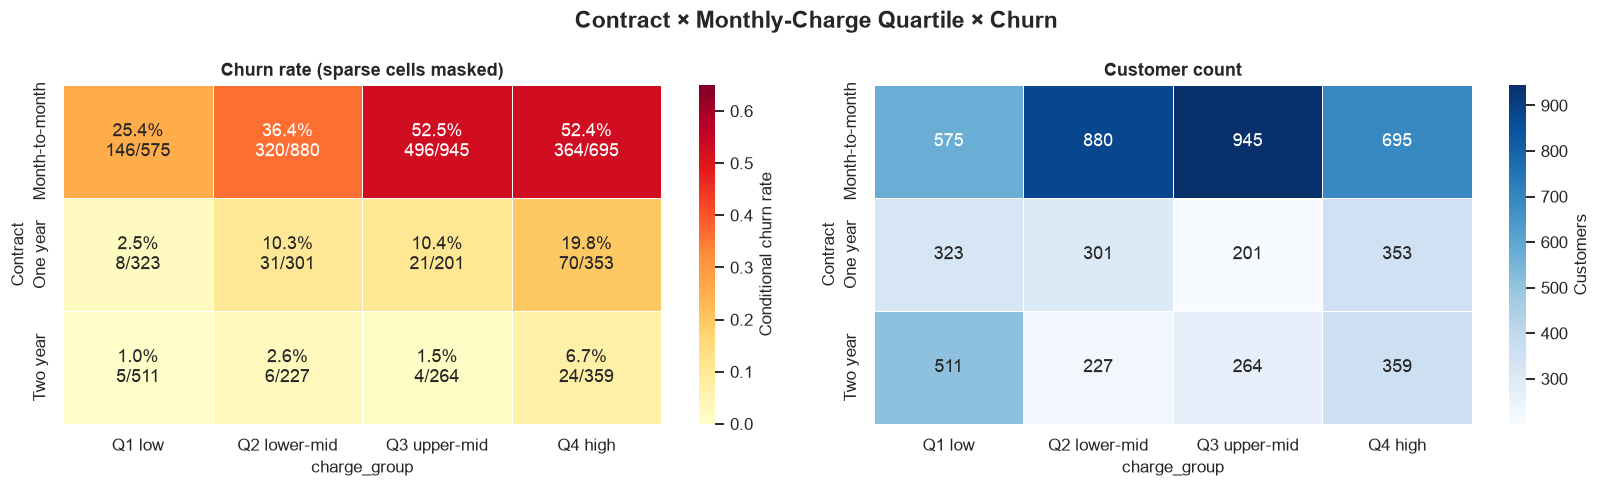

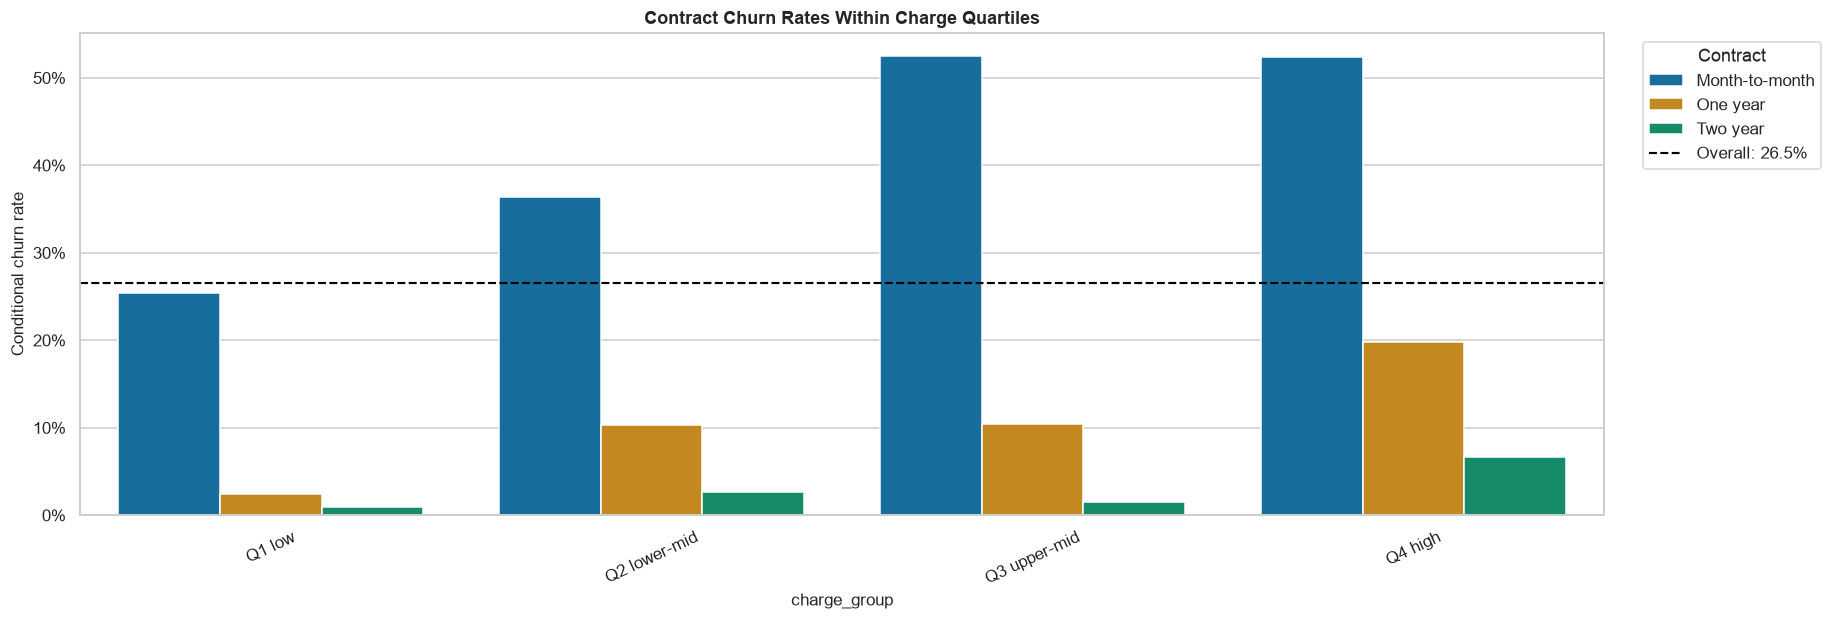

In [12]:
# ruff: noqa: E501
contract_charge = conditional_table(
    analysis_df,
    "Contract",
    "charge_group",
    contract_order,
    charge_labels,
)
display(contract_charge)
plot_heatmaps(
    contract_charge,
    "Contract",
    "charge_group",
    "Contract × Monthly-Charge Quartile × Churn",
)
plot_grouped_rates(
    contract_charge,
    "charge_group",
    "Contract",
    "Contract Churn Rates Within Charge Quartiles",
)

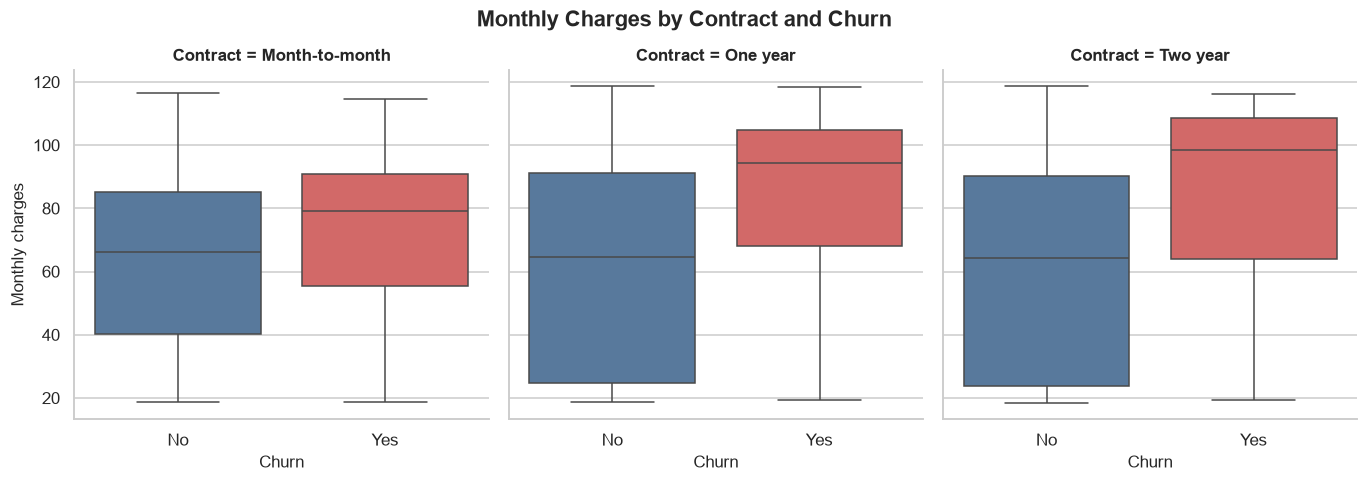

In [13]:
# ruff: noqa: E501
contract_charge_grid = sns.catplot(
    data=analysis_df,
    x=target_column,
    y="MonthlyCharges",
    order=target_order,
    hue=target_column,
    palette=target_colors,
    legend=False,
    col="Contract",
    col_order=contract_order,
    kind="box",
    height=4.2,
    aspect=1.0,
)
contract_charge_grid.set_axis_labels("Churn", "Monthly charges")
contract_charge_grid.fig.suptitle(
    "Monthly Charges by Contract and Churn",
    y=1.04,
    fontweight="bold",
)
plt.show()

**Observed finding.** Month-to-month churn rises from 25.39% in Q1 to 52.49% in Q3 and
52.37% in Q4. One-year rates range from 2.48% to 19.83%; two-year rates remain below 6.69%
in every charge quartile. All 12 combinations have at least 201 customers. Commitment and
price show changing joint rates, but no formal interaction test or causal adjustment is
performed.

# 8. Numerical multivariate analysis

Pair plots show all pairwise projections with churn colouring; scatter facets then display
tenure versus accumulated charges while colour encodes monthly price. Hexbin facets reduce
overplotting by counting nearby observations.

Interpretation focuses on overlap, nonlinearity, heteroscedasticity, and possible
redundancy. No formal correlation, VIF, PCA, clustering, regression, or multicollinearity
analysis is performed.

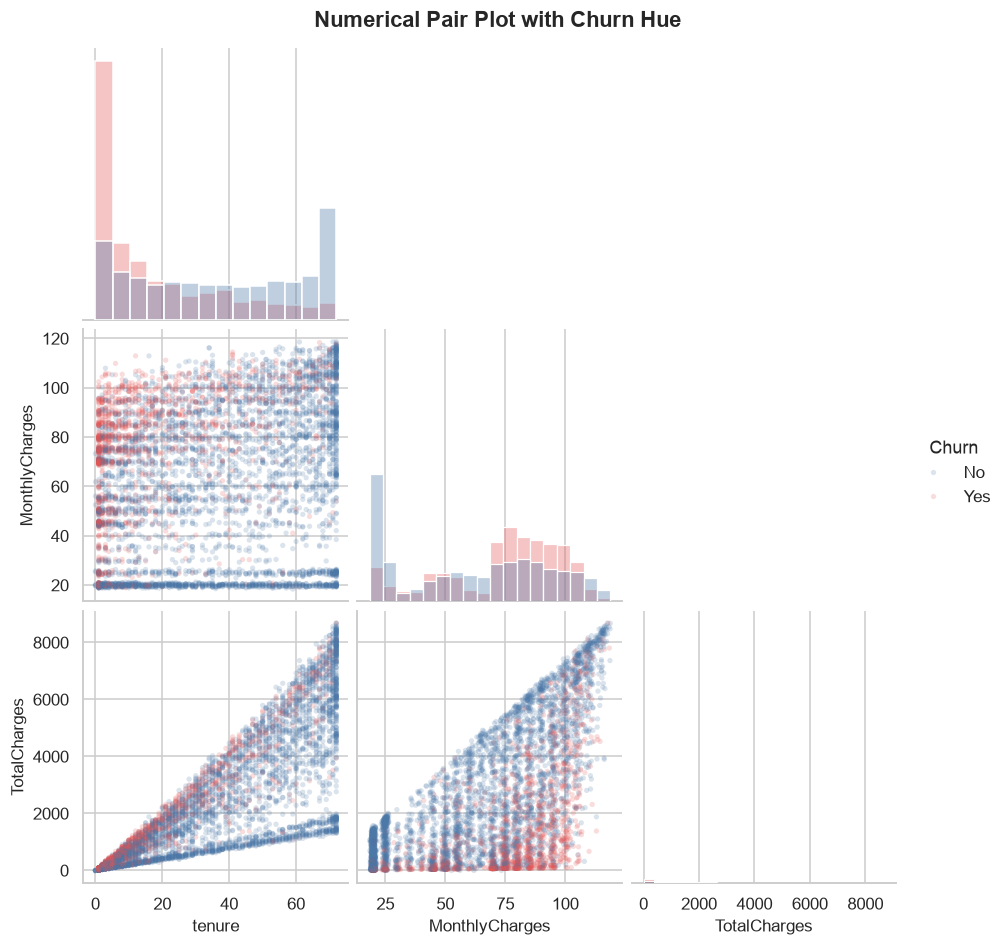

In [14]:
# ruff: noqa: E501
pair_grid = sns.pairplot(
    analysis_df[numerical_features + [target_column]],
    vars=numerical_features,
    hue=target_column,
    hue_order=target_order,
    palette=target_colors,
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.20, "s": 12, "edgecolor": "none"},
    diag_kws={"stat": "density", "common_norm": False, "alpha": 0.35},
    height=2.8,
)
pair_grid.fig.suptitle("Numerical Pair Plot with Churn Hue", y=1.02, fontweight="bold")
plt.show()

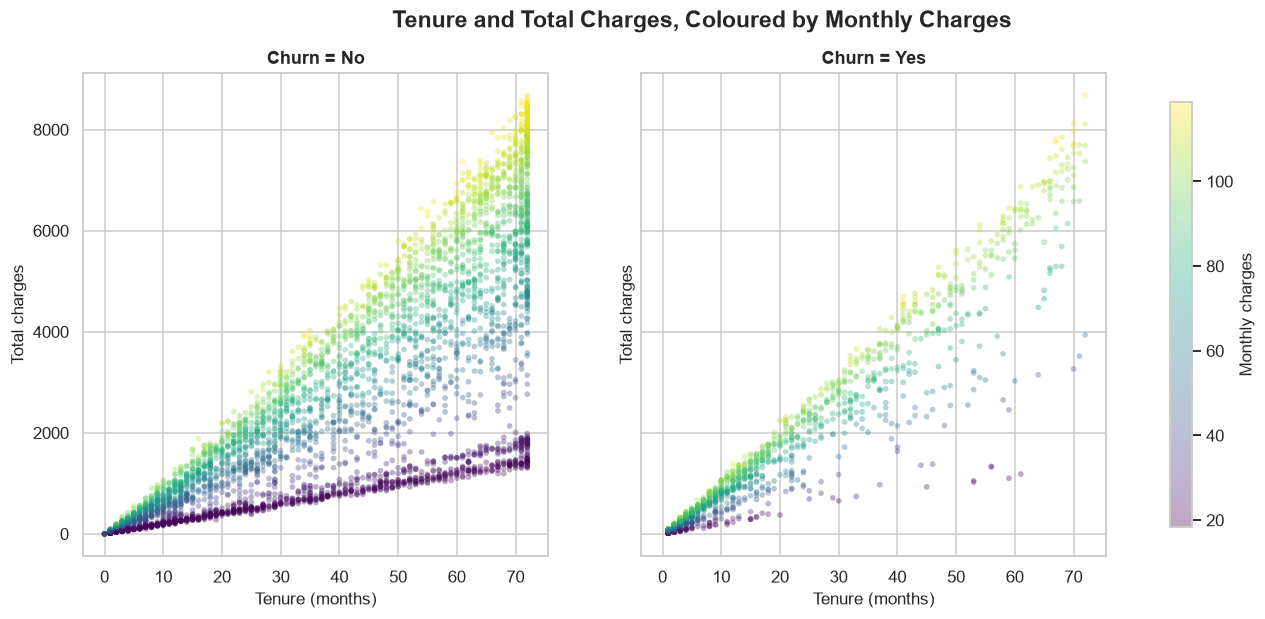

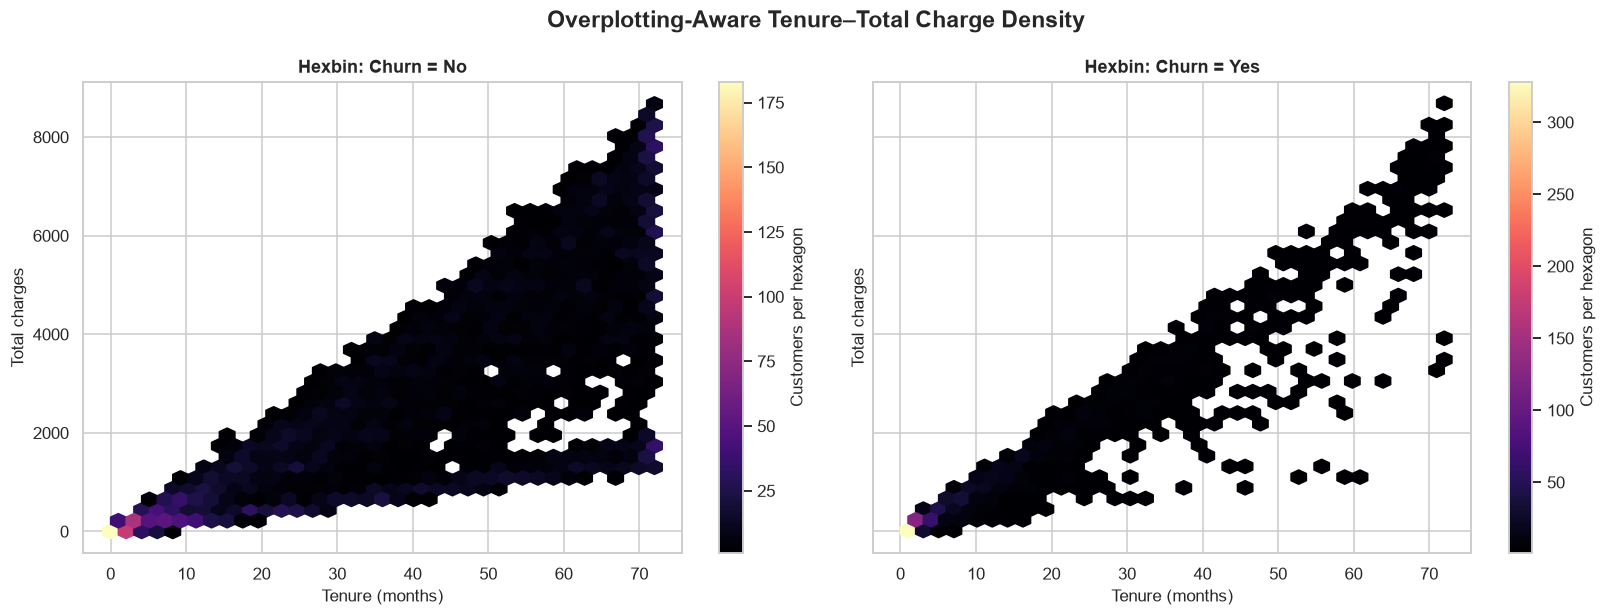

In [15]:
# ruff: noqa: E501
fig, axes = plt.subplots(1, 2, figsize=(15, 5.7), sharex=True, sharey=True)
normalizer = colors.Normalize(
    vmin=analysis_df["MonthlyCharges"].min(),
    vmax=analysis_df["MonthlyCharges"].max(),
)
for axis, churn_class in zip(axes, target_order, strict=True):
    subset = analysis_df.loc[analysis_df[target_column].eq(churn_class)]
    scatter = axis.scatter(
        subset["tenure"],
        subset["TotalCharges"],
        c=subset["MonthlyCharges"],
        cmap="viridis",
        norm=normalizer,
        alpha=0.35,
        s=14,
        edgecolors="none",
    )
    axis.set(
        title=f"Churn = {churn_class}",
        xlabel="Tenure (months)",
        ylabel="Total charges",
    )
fig.colorbar(scatter, ax=axes, label="Monthly charges", shrink=0.88)
fig.suptitle("Tenure and Total Charges, Coloured by Monthly Charges", fontsize=15, fontweight="bold")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.7), sharex=True, sharey=True)
for axis, churn_class in zip(axes, target_order, strict=True):
    subset = analysis_df.loc[analysis_df[target_column].eq(churn_class)]
    hexbin = axis.hexbin(
        subset["tenure"],
        subset["TotalCharges"],
        gridsize=35,
        mincnt=1,
        cmap="magma",
    )
    axis.set(
        title=f"Hexbin: Churn = {churn_class}",
        xlabel="Tenure (months)",
        ylabel="Total charges",
    )
    fig.colorbar(hexbin, ax=axis, label="Customers per hexagon")
fig.suptitle("Overplotting-Aware Tenure–Total Charge Density", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

**Observed finding.** Total charges increase in a heteroscedastic fan as tenure grows;
monthly charge explains much of the vertical spread at a given tenure. The relationship is
structured rather than a single constant-slope cloud, and retained/churned observations
overlap broadly. Churned customers concentrate toward shorter tenure and lower accumulated
charges while often carrying higher monthly prices. `TotalCharges` therefore contains
information related to both tenure and recurring price and may be partially redundant, but
formal redundancy analysis is deferred.

# 9. Marginal versus stratified association and Simpson audit

For selected comparisons, the code records the marginal rate difference and each
stratum-specific difference. A reversal flag requires the marginal and conditional signs
to oppose each other. Missing comparisons are excluded rather than treated as zero.

Changing magnitudes across strata can suggest interaction/effect modification, but without
formal models, uncertainty, or causal assumptions we describe only observed heterogeneity.

In [16]:
# ruff: noqa: E501
def marginal_rate(feature: str, category: str) -> float:
    values = analysis_df.loc[analysis_df[feature].eq(category), target_column]
    return values.eq("Yes").mean()


comparison_specifications = [
    ("PaymentMethod", "Electronic check", "Mailed check", "tenure_group", tenure_labels),
    ("PaymentMethod", "Electronic check", "Bank transfer (automatic)", "tenure_group", tenure_labels),
    ("PaymentMethod", "Electronic check", "Credit card (automatic)", "tenure_group", tenure_labels),
    ("Contract", "Month-to-month", "One year", "tenure_group", tenure_labels),
    ("Contract", "Month-to-month", "Two year", "tenure_group", tenure_labels),
    ("InternetService", "Fiber optic", "DSL", "charge_group", charge_labels),
    ("TechSupport", "No", "Yes", "InternetService", ["DSL", "Fiber optic"]),
    ("OnlineSecurity", "No", "Yes", "InternetService", ["DSL", "Fiber optic"]),
]

simpson_rows = []
for feature, category_a, category_b, stratifier, strata in comparison_specifications:
    marginal_difference = marginal_rate(feature, category_a) - marginal_rate(feature, category_b)
    for stratum in strata:
        subset = analysis_df.loc[analysis_df[stratifier].eq(stratum)]
        a_values = subset.loc[subset[feature].eq(category_a), target_column]
        b_values = subset.loc[subset[feature].eq(category_b), target_column]
        if len(a_values) == 0 or len(b_values) == 0:
            conditional_difference = np.nan
            reversal = False
        else:
            conditional_difference = a_values.eq("Yes").mean() - b_values.eq("Yes").mean()
            reversal = np.sign(conditional_difference) == -np.sign(marginal_difference)
        simpson_rows.append({
            "feature": feature,
            "category_A": category_a,
            "category_B": category_b,
            "stratifier": stratifier,
            "stratum": str(stratum),
            "marginal_rate_difference_A_minus_B": marginal_difference,
            "conditional_rate_difference_A_minus_B": conditional_difference,
            "A_count": len(a_values),
            "B_count": len(b_values),
            "direction_reversal": reversal,
        })

simpson_audit = pd.DataFrame(simpson_rows)
display(simpson_audit)
display(Markdown(
    f"**Result:** {int(simpson_audit['direction_reversal'].sum())} observed stratum comparisons reverse "
    "the marginal direction. The examined associations retain their direction where comparison is possible, "
    "although magnitudes vary substantially. Therefore this analysis does **not** demonstrate Simpson's paradox."
))

,feature,category_A,category_B,stratifier,stratum,marginal_rate_difference_A_minus_B,conditional_rate_difference_A_minus_B,A_count,B_count,direction_reversal
0,PaymentMethod,Electronic check,Mailed check,tenure_group,0–6,0.263,0.294,540,453,False
1,PaymentMethod,Electronic check,Mailed check,tenure_group,7–12,0.263,0.304,228,170,False
2,PaymentMethod,Electronic check,Mailed check,tenure_group,13–24,0.263,0.405,298,220,False
3,PaymentMethod,Electronic check,Mailed check,tenure_group,25–48,0.263,0.255,416,246,False
4,PaymentMethod,Electronic check,Mailed check,tenure_group,49–72,0.263,0.206,395,207,False
5,PaymentMethod,Electronic check,Bank transfer (automatic),tenure_group,0–6,0.295,0.142,540,94,False
6,PaymentMethod,Electronic check,Bank transfer (automatic),tenure_group,7–12,0.295,0.164,228,94,False
7,PaymentMethod,Electronic check,Bank transfer (automatic),tenure_group,13–24,0.295,0.297,298,148,False
8,PaymentMethod,Electronic check,Bank transfer (automatic),tenure_group,25–48,0.295,0.173,416,305,False
9,PaymentMethod,Electronic check,Bank transfer (automatic),tenure_group,49–72,0.295,0.157,395,605,False


**Result:** 0 observed stratum comparisons reverse the marginal direction. The examined associations retain their direction where comparison is possible, although magnitudes vary substantially. Therefore this analysis does **not** demonstrate Simpson's paradox.

# 10. Business interpretation and candidate future features

## Supported findings

- Early-life month-to-month customers have the largest well-supported joint rate: 55.31%
  for 0–6 months (625/1,130). Contract differences persist across tenure bands.
- Electronic check remains elevated within every tenure band; 0–6 months reaches 67.41%
  (364/540). Tenure confounds the marginal comparison but does not fully explain it.
- Fibre remains above DSL within overlapping price quartiles, but service-specific price
  ranges have poor common support, limiting direct comparison.
- Among internet subscribers, lacking both technical support and online security coincides
  with 48.93% churn (1,003/2,050); having both coincides with 8.91% (78/875).
- High-price month-to-month groups show rates around 52%, whereas two-year groups remain
  below 7% across charge quartiles.

## Candidate feature-engineering ideas for later validation

Potential candidates include tenure bands, contract × tenure, payment × tenure,
internet-service × price band, contract × price band, support/security adoption state, and
tenure–monthly-charge combinations. These are hypotheses—not production features. Later
work must define them inside leakage-safe training pipelines, test stability, handle sparse
and unseen combinations, and compare out-of-fold utility against simpler specifications.

No intervention is proven effective: changing contract, payment method, support, or
security could have different outcomes because observed customers self-select these states.

# 11. Interview questions with speakable answers

### 1. How did tenure confound the payment-method association?

**Speakable answer:** “Electronic-check customers are shorter-tenured, and churn declines
with tenure for every payment method. That lifecycle imbalance inflates the marginal
comparison. However, electronic check still has the highest rate within each tenure band,
so coarse tenure stratification does not fully explain the association. I would not call
payment method causal without formal adjustment and a causal design.”

### 2. Did this analysis find Simpson's paradox?

**Speakable answer:** “No. Simpson's paradox requires a direction reversal between the
aggregate and relevant stratified associations. The contract, payment, fibre-versus-DSL,
support, and security comparisons retained their marginal direction wherever overlap
allowed comparison. Their magnitudes changed, which can suggest heterogeneity, but that is
not a Simpson reversal.”

### 3. What is the difference between interaction and confounding?

**Speakable answer:** “Confounding distorts an association because a third variable is
related to both exposure and outcome. Interaction means the association itself differs
across levels of another variable. Here tenure is a plausible confounder for payment and
contract, while changing gaps across tenure bands suggest possible interaction. Formal
claims require models and uncertainty estimates that are outside this phase.”

### 4. Why mask a sparse zero-churn cell?

**Speakable answer:** “Zero observed churn is not proof of zero underlying risk. In the
two-year, 0–6-month cell only 25 customers are observed, so one event would move the rate
by four percentage points. I preserve the count and zero events in the table, label the
cell sparse, and mask its rate in the heatmap rather than presenting it as a reliable
low-risk segment.”

# 12. Verification and remaining limitations

- Strata are coarse and data-dependent; residual confounding remains within groups.
- Empty service-price cells show limited common support.
- Conditional rates lack confidence intervals and formal significance tests.
- Multiple exploratory comparisons can highlight unstable patterns by chance.
- No formal correlation/association coefficients, outlier analysis, regression,
  multicollinearity analysis, PCA, clustering, feature selection, or modelling is included.
- The snapshot lacks timing, plan changes, interventions, costs, and causal identification.

In [17]:
# ruff: noqa: E501
def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for block in iter(lambda: file.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


previous_notebook_hashes = {
    "01_exploratory_data_analysis.ipynb": "970288d8018d13770f972835b4ecc86fe7857e28c0b7447b104fa5b3edcf662b",
    "02_univariate_analysis.ipynb": "0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8edef76e26d61b851de4a",
    "03_bivariate_analysis.ipynb": "1ec80ddc2eb412b604841a20afa78e5199903ff00206f4e291a48a16d655d495",
}
for notebook_name, expected_hash in previous_notebook_hashes.items():
    actual_hash = sha256(PROJECT_ROOT / "notebooks" / notebook_name)
    assert actual_hash == expected_hash, f"Previous notebook changed: {notebook_name}"
    print(f"Verified unchanged: {notebook_name} ({actual_hash})")

assert development_path == (PROJECT_ROOT / "data/processed/development.parquet").resolve()
assert df.shape == (5_634, 21)
assert len(analysis_df) == len(df)
assert not simpson_audit["direction_reversal"].any()
assert analysis_df["tenure_group"].notna().all()
assert analysis_df["charge_group"].notna().all()

print("Leakage audit passed: one configured development Parquet input was loaded.")
print("Temporary groups remained notebook-local; no dataset or feature artifact was written.")
print("No hypothesis test, p-value, formal correlation/association coefficient, outlier removal, or model was run.")

Verified unchanged: 01_exploratory_data_analysis.ipynb (970288d8018d13770f972835b4ecc86fe7857e28c0b7447b104fa5b3edcf662b)
Verified unchanged: 02_univariate_analysis.ipynb (0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8edef76e26d61b851de4a)
Verified unchanged: 03_bivariate_analysis.ipynb (1ec80ddc2eb412b604841a20afa78e5199903ff00206f4e291a48a16d655d495)
Leakage audit passed: one configured development Parquet input was loaded.
Temporary groups remained notebook-local; no dataset or feature artifact was written.
No hypothesis test, p-value, formal correlation/association coefficient, outlier removal, or model was run.
